
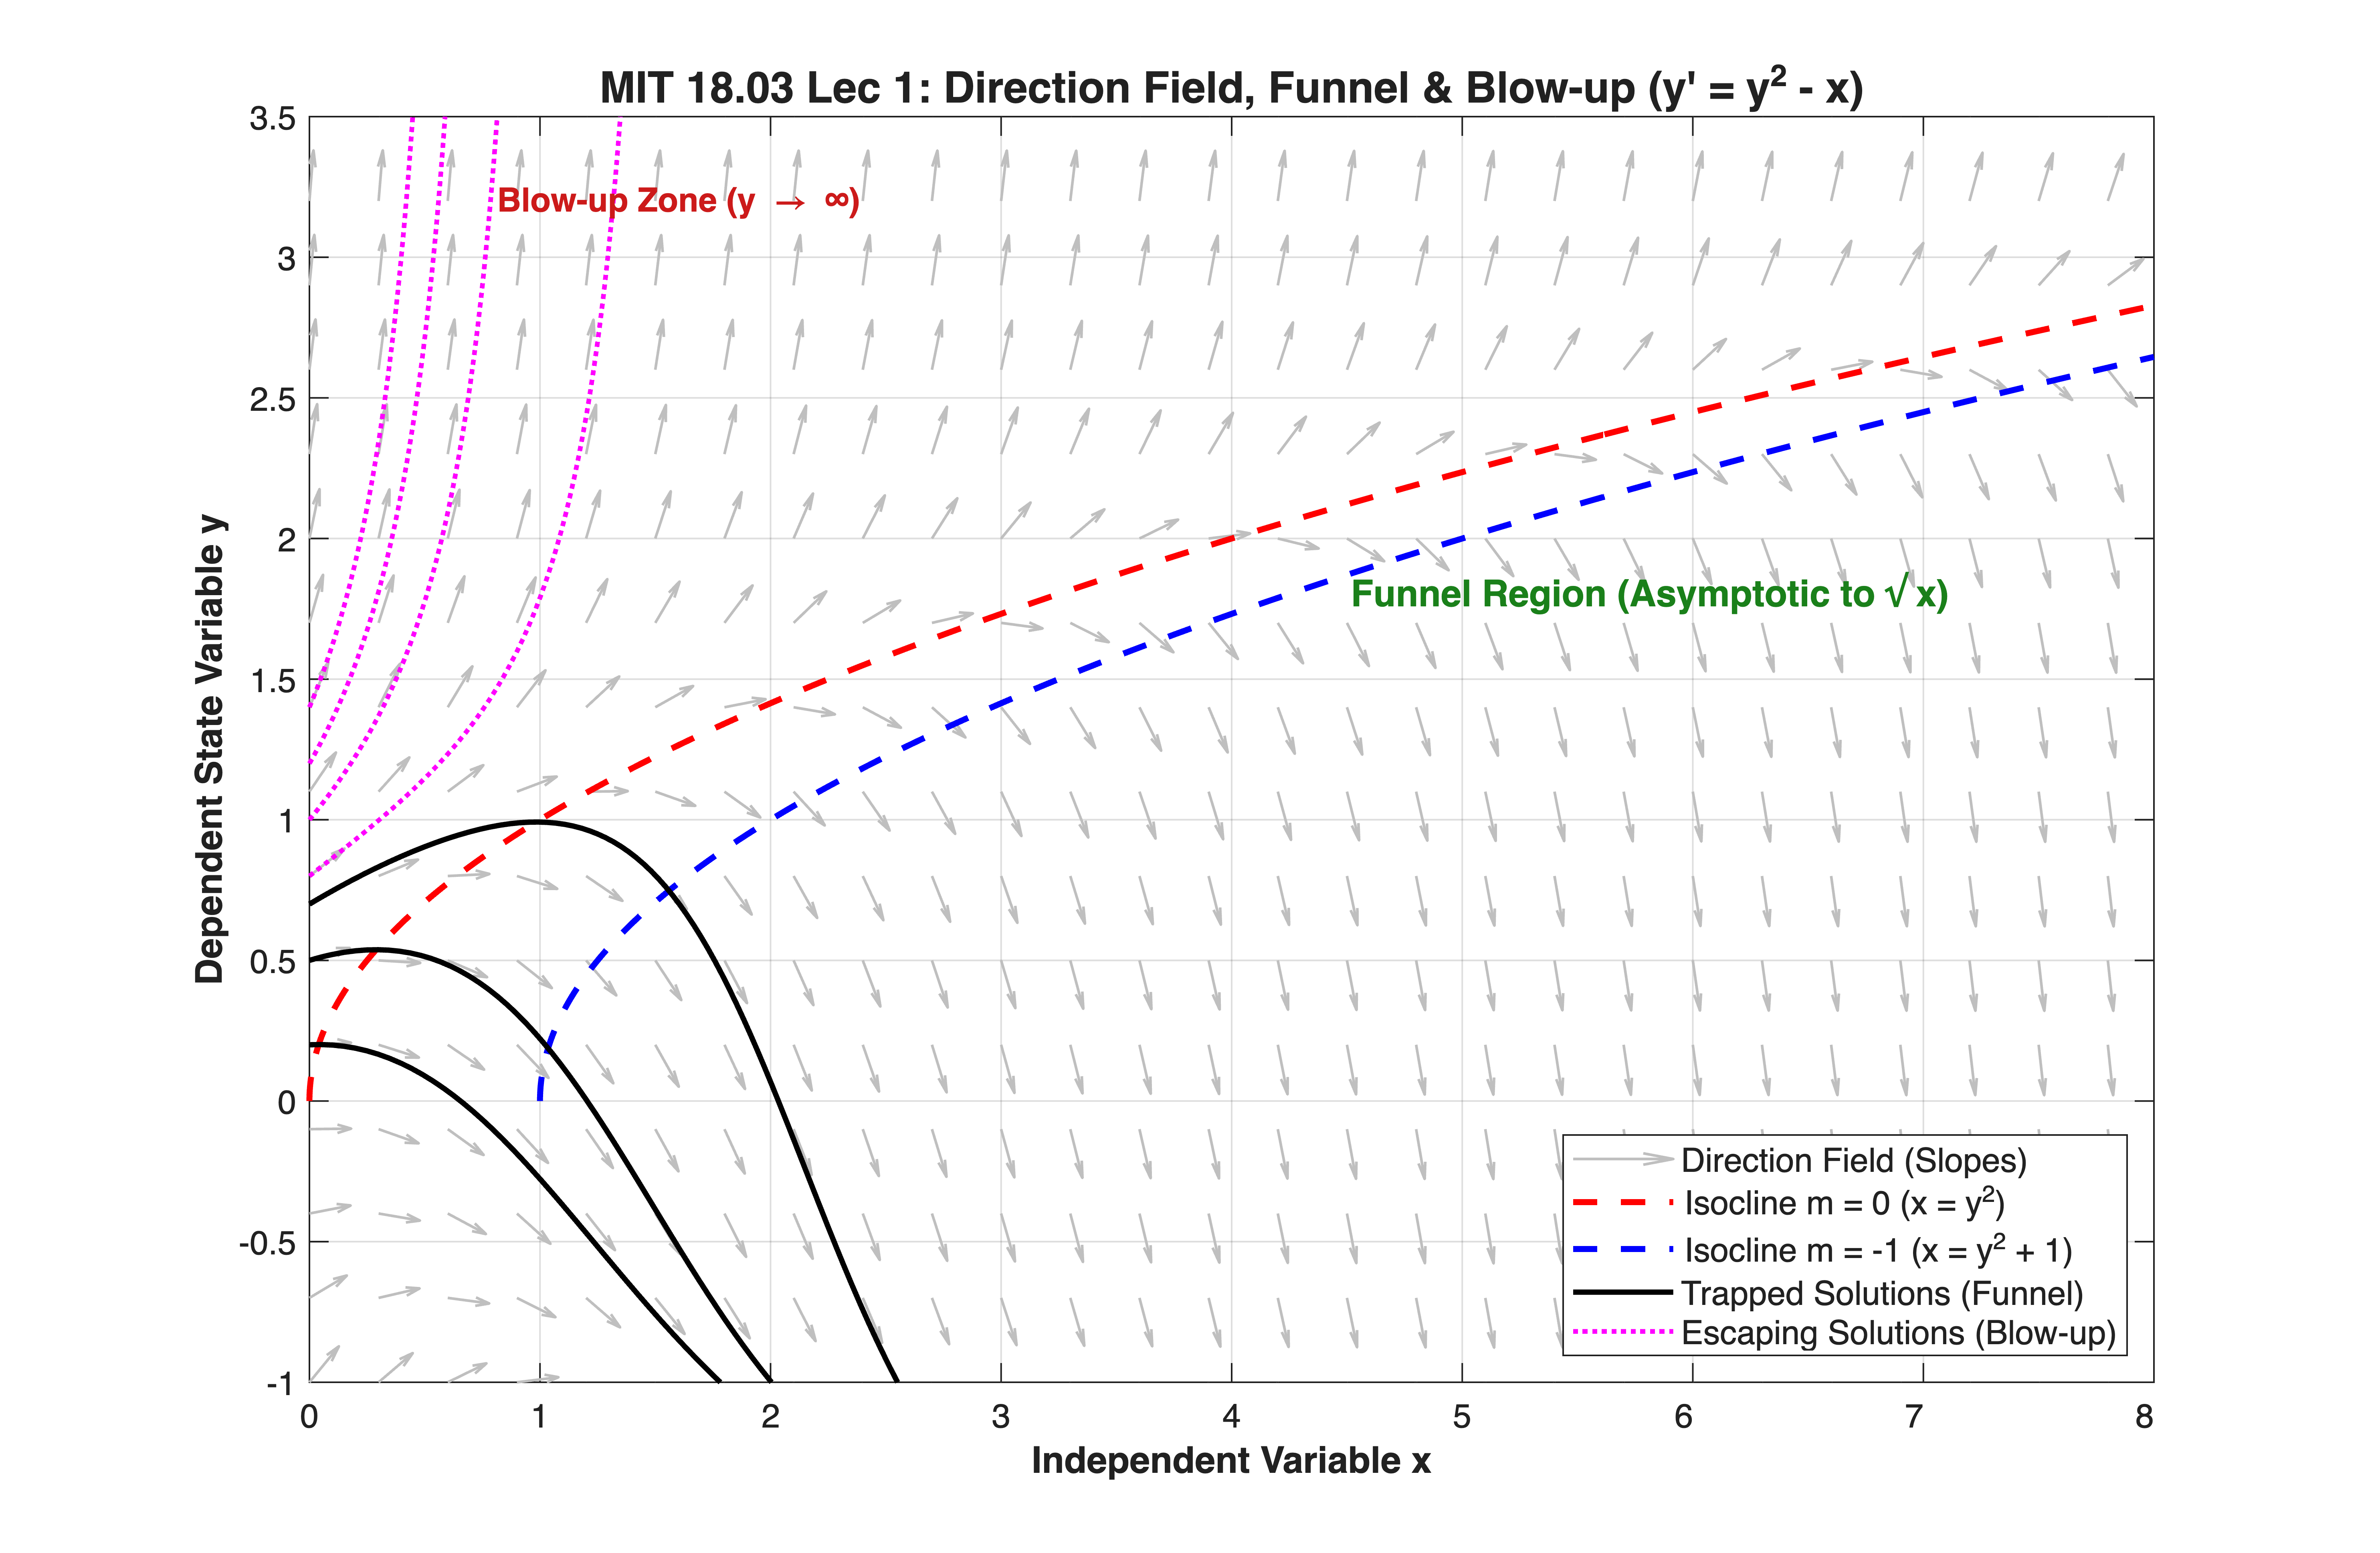

In [1]:
%% MIT 18.03 Lecture 1: Nonlinear Direction Field & Funnel Dynamics (Robust Version)
% Description: Visualizes the slope field, isoclines (m = 0, m = -1),
%              and state trajectories of y' = y^2 - x using an ODE Event Function
%              to prevent step-size underflow caused by finite-time blow-ups.
% MBD Concept Mapping: Demonstrates state trajectories entering an invariant
%                      funnel zone versus escaping trajectories, while employing
%                      zero-crossing event detection to handle state boundary limits.


clear; clc; close all;


%% 1. Grid Definition for Direction Field
x_min = 0;   x_max = 8;
y_min = -1;  y_max = 3.5;
grid_step = 0.3;


[X, Y] = meshgrid(x_min:grid_step:x_max, y_min:grid_step:y_max);


% Differential Equation: dy/dx = F(x, y) = y^2 - x
Slope = Y.^2 - X;


% Normalize direction vectors for uniform quiver arrows
L = sqrt(1 + Slope.^2);
U = 1 ./ L;
V = Slope ./ L;


%% 2. Figure Setup & Slope Field Plotting
figure('Color', [1 1 1], 'Position', [150, 150, 950, 620]);
hold on; grid on; box on;


% Plot normalized slope vectors
quiver(X, Y, U, V, 0.45, 'Color', [0.75 0.75 0.75], 'LineWidth', 0.8, ...
       'DisplayName', 'Direction Field (Slopes)');


%% 3. Plot Isoclines (Funnel Boundaries)
% Isocline m = 0: x = y^2 -> y = sqrt(x)
% Isocline m = -1: x = y^2 + 1 -> y = sqrt(x - 1)
y_iso = linspace(0, y_max, 300);
x_iso_0  = y_iso.^2;
x_iso_m1 = y_iso.^2 + 1;


plot(x_iso_0, y_iso, 'r--', 'LineWidth', 1.8, ...
     'DisplayName', 'Isocline m = 0 (x = y^2)');
plot(x_iso_m1, y_iso, 'b--', 'LineWidth', 1.8, ...
     'DisplayName', 'Isocline m = -1 (x = y^2 + 1)');


%% 4. Numerical Integration with Event Termination
% MBD Concept Mapping: Event detection stops integration cleanly when y reaches y_max
ode_fun = @(x, y) y^2 - x;
x_span = [0, x_max];


% Configure ODE options with Event Function to cleanly halt blow-up solutions
opts = odeset('RelTol', 1e-6, 'AbsTol', 1e-8, ...
              'Events', @(x, y) event_state_boundary(x, y, y_max));


% Representative initial conditions crossing the separatrix
initial_conditions = [0.2, 0.5, 0.7, 0.8, 1.0, 1.2, 1.4];


for idx = 1:length(initial_conditions)
    y0 = initial_conditions(idx);

    [x_sol, y_sol, te, ye, ie] = ode45(ode_fun, x_span, y0, opts);

    % Categorize trajectories based on whether an event termination occurred
    if isempty(te)
        % Trajectory remained within bounds and entered the funnel
        plot(x_sol, y_sol, 'k-', 'LineWidth', 1.6, 'HandleVisibility', 'off');
    else
        % Trajectory escaped and terminated at y = y_max
        plot(x_sol, y_sol, 'm:', 'LineWidth', 1.4, 'HandleVisibility', 'off');
    end
end


% Dummy plots for clear legend labeling
plot(NaN, NaN, 'k-', 'LineWidth', 1.6, 'DisplayName', 'Trapped Solutions (Funnel)');
plot(NaN, NaN, 'm:', 'LineWidth', 1.4, 'DisplayName', 'Escaping Solutions (Blow-up)');


%% 5. Formatting & Annotations
xlim([x_min, x_max]);
ylim([y_min, y_max]);
xlabel('Independent Variable x', 'FontSize', 11, 'FontWeight', 'bold');
ylabel('Dependent State Variable y', 'FontSize', 11, 'FontWeight', 'bold');
title("MIT 18.03 Lec 1: Direction Field, Funnel & Blow-up (y' = y^2 - x)", ...
      'FontSize', 13, 'FontWeight', 'bold');
legend('Location', 'southeast', 'FontSize', 10);


% Annotate dynamic zones
text(4.5, 1.8, 'Funnel Region (Asymptotic to \surd x)', ...
     'FontSize', 11, 'FontWeight', 'bold', 'Color', [0.1 0.5 0.1]);
text(0.8, 3.2, 'Blow-up Zone (y \rightarrow \infty)', ...
     'FontSize', 10, 'FontWeight', 'bold', 'Color', [0.8 0.1 0.1]);


hold off;

In [2]:


%% Local Event Function
function [value, isterminal, direction] = event_state_boundary(~, y, y_bound)
% EVENT_STATE_BOUNDARY Halts integration when y exceeds y_bound.
%
% MBD Concept Mapping: Emulates system saturation and numerical boundary
%                      guards in dynamical state-space integration.
    value = y - y_bound;  % Trigger when y(t) - y_bound = 0
    isterminal = 1;       % Stop the integration immediately
    direction = 1;        % Positive crossing direction only
end